# BA focal observability

Quantify how a wrong **shared** focal length is absorbed by BA (along-track stretch).
Equations: https://claude.ai/artifact/EXEZWUqjQmULnEAthyKTu9

## Step 1: Jacobian of one observation

$J_{ij} = \big[\ \partial(u,v)/\partial(f,k_1)\ \big|\ \partial(u,v)/\partial\omega\ \big|\ \partial(u,v)/\partial t\ \big|\ \partial(u,v)/\partial X\ \big]$, size $2 \times 11$

In [1]:
# Load April COLMAP model (one shared SIMPLE_RADIAL camera)
import numpy as np
from ba_obs import load_colmap_txt, project, jacobian_obs, jacobian_fd

cams, ims, pts = load_colmap_txt('../datasets/KBCB_colm_april')
print(f"{len(cams)} camera(s), {len(ims)} images, {len(pts)} points")
print("f, cx, cy, k1 =", cams[1])

1 camera(s), 121 images, 52484 points
f, cx, cy, k1 = (1906.0899992591642, 1224.0, 688.0, -0.09865326299992969)


In [2]:
# Jacobian for the observations of one image
im = ims[1]
f, cx, cy, k1 = cams[im['cam']]
X = np.array([pts[p] for p in im['pid']])

J = jacobian_obs(f, k1, cx, cy, im['R'], im['t'], X)
print(im['name'], J.shape)

# Sanity: projection reproduces the detected pixels
err = np.linalg.norm(project(f, k1, cx, cy, im['R'], im['t'], X) - im['xy'], axis=1)
print(f"reprojection error px: median {np.median(err):.2f}, max {err.max():.2f}")

frame_25839.jpg (2443, 2, 11)
reprojection error px: median 0.44, max 3.86


In [3]:
# Check analytic Jacobian against finite differences (first 50 observations)
n = 50
J_fd = jacobian_fd(f, k1, cx, cy, im['R'], im['t'], X[:n])

for name, sl in [('f, k1', slice(0,2)), ('w', slice(2,5)), ('t', slice(5,8)), ('X', slice(8,11))]:
    rel = np.abs(J[:n,:,sl] - J_fd[...,sl]).max() / np.abs(J_fd[...,sl]).max()
    print(f"{name:6s} max relative error {rel:.1e}")

f, k1  max relative error 3.8e-10
w      max relative error 2.5e-11
t      max relative error 4.2e-11
X      max relative error 1.5e-10


## Step 2: Hessian

Stack all observations into one sparse $J$, then $H = J^\top W J$ with $W = I/\sigma^2$.

- Diagonal: how clearly BA sees each parameter
- Off-diagonal: coupling between two parameters

Simplification: single isotropic pixel noise $\sigma = 0.5$ px (from median reprojection error)

In [4]:
# Full sparse Jacobian and Hessian
from ba_obs import build_jacobian

J, im_ids, pt_ids = build_jacobian(cams, ims, pts)
sigma = 0.5
H = (J.T @ J) / sigma**2

print(f"J {J.shape}, {J.nnz/np.prod(J.shape):.1e} filled")
print(f"H {H.shape}, {H.nnz/np.prod(H.shape):.1e} filled")
print(f"H_ff = {H[0,0]:.3e}, H_k1k1 = {H[1,1]:.3e}")

J (555502, 158180), 7.0e-05 filled
H (158180, 158180), 4.4e-04 filled
H_ff = 1.571e+05, H_k1k1 = 4.399e+10


## Step 3: Gauge choice

Fix 7 parameters:
- Pose of first image (6): shift + rotation
- World $Y$ of one ground point below camera 1 (1): scale, fixed vertically so the along-track stretch stays free

Applied inside `reduced_hessian` (Step 4): deleting rows/cols of the reduced Hessian = deleting columns of $J$.

Simplification: world axes $\approx$ first camera axes ($R \approx I$), so $Y$ = down, $Z$ = along-track

In [5]:
# Gauge: ground point nearest bottom-center pixel of first image (any well-tracked ground point works)
im0 = ims[im_ids[0]]
print(im0['name'], "R =\n", im0['R'].round(3))

n = np.argmin(np.linalg.norm(im0['xy'] - [1224, 1100], axis=1))
pid_fix = im0['pid'][n]
print("fixed point", pid_fix, "pixel", im0['xy'][n].round(1), "world", pts[pid_fix].round(3))

frame_25839.jpg R =
 [[ 1.     0.009 -0.021]
 [-0.009  1.     0.006]
 [ 0.021 -0.006  1.   ]]
fixed point 55643 pixel [1225.8 1106. ] world [-0.047  0.099 -5.231]


## Step 4: Schur out the points

$$S = H_{cc} - H_{cX}\,H_{XX}^{-1}\,H_{Xc}$$

$H_{XX}$ is block diagonal (3×3 per point), so it inverts block by block. $S$ is over $c = [f, k_1, \text{poses}]$.

Check: without the gauge fix, $S$ should have exactly 7 zero eigenvalues; with it, none.

In [6]:
# Reduced Hessian, with and without gauge fix
from ba_obs import reduced_hessian

S0 = reduced_hessian(J, im_ids, pt_ids, sigma)              # [f, k1, all poses]
S = reduced_hessian(J, im_ids, pt_ids, sigma, pid_fix)      # [f, k1, poses of im_ids[1:]]
print("S0", S0.shape, " S", S.shape)

# f column in relative units (df/f) so eigenvalues compare across parameters
D0 = np.r_[f, np.ones(len(S0)-1)]
D = np.r_[f, np.ones(len(S)-1)]
ev0 = np.linalg.eigvalsh(D0[:,None] * S0 * D0)
print("no gauge, 9 smallest / largest:", (ev0[:9] / ev0[-1]).round(16))

S0 (728, 728)  S (722, 722)
no gauge, 9 smallest / largest: [-4.000000e-16 -0.000000e+00 -0.000000e+00  0.000000e+00  0.000000e+00
  0.000000e+00  1.000000e-16  8.310220e-11  2.786973e-10]


## Step 5: Weak directions

Eigenvectors of $S$ with the smallest eigenvalues = parameter combinations the data can barely tell apart.
- `f share`: $|v_f|$, how much of each weak direction is focal length
- $\sigma_f = \sqrt{(S^{-1})_{ff}}$: how well $f$ is determined from pixel noise alone

Simplification: mixed units (relative $f$, radians, COLMAP lengths), so eigenvalue ordering is only indicative

In [7]:
# Smallest eigenvalues of gauge-fixed S and how much f is in each
ev, V = np.linalg.eigh(D[:,None] * S * D)
for k in range(8):
    print(f"{k}  eig/max {ev[k]/ev[-1]:.1e}   f share {abs(V[0,k]):.3f}")

sigma_f = np.sqrt(np.linalg.inv(S)[0,0])
print(f"\nsigma_f = {sigma_f:.2f} px  ({100*sigma_f/f:.2f}% of f)")

0  eig/max 6.1e-12   f share 0.007
1  eig/max 8.9e-11   f share 0.014
2  eig/max 2.8e-10   f share 0.015
3  eig/max 1.4e-08   f share 0.003
4  eig/max 8.1e-08   f share 0.193
5  eig/max 1.1e-07   f share 0.613
6  eig/max 5.7e-07   f share 0.113
7  eig/max 9.5e-07   f share 0.017

sigma_f = 4.77 px  (0.25% of f)


## Step 6: Focal error -> along-track stretch

Hold $f$ wrong by $\delta f$, let everything else re-adjust (linear):

$$\delta c = -S_{cc}^{-1}\,S_{cf}\,\delta f, \qquad \delta C = -R^\top(\delta t + t \times \delta\omega)$$

Stretch $\alpha$ = least-squares slope of along-track shift vs along-track position, per 1% focal error.

Simplification: images with < 500 observations treated as misregistered (April: frame_26259) and left out of the fit

In [8]:
# Linear camera-center shift for a +1% focal error
from ba_obs import focal_bias, cam_centers, ground_plane, track_axes

dC, dk1 = focal_bias(S, ims, im_ids, 0.01*f)
C = cam_centers(ims, im_ids)

good = np.array([len(ims[i]['pid']) >= 500 for i in im_ids])
t_order = np.argsort([ims[i]['name'] for i in im_ids])
t_order = t_order[good[t_order]]
g0, nrm = ground_plane(ims, pts, im_ids)
a, h = track_axes(C[t_order], g0, nrm)

s_al, d_al = ((C - C[0]) @ a)[good], (dC @ a)[good]
alpha = (s_al @ d_al) / (s_al @ s_al)
lat = np.cross(nrm, a)
print(f"along-track stretch per 1% focal error: {100*alpha:.2f}%")
print(f"max shift (COLMAP units)  along {abs(d_al).max():.4f}   lateral {abs(dC[good] @ lat).max():.4f}   vertical {abs(dC[good] @ nrm).max():.4f}")
print(f"track length {np.ptp(s_al)/h:.0f} camera heights,  dk1 = {dk1:.4f}")

along-track stretch per 1% focal error: 1.02%
max shift (COLMAP units)  along 0.1228   lateral 0.0014   vertical 0.0008
track length 120 camera heights,  dk1 = -0.0018


## Step 7: Validate against April vs VT

Two real reconstructions of the same 121 images: April ($f$ = 1906, refined) and VT ($f$ = 1615, fixed).
Along-track positions in camera-height units (gauge free), relative to the same reference image.

Predicted (linear, Step 6): $\;s_{VT}/s_{April} \approx 1 + \alpha \cdot 100\,(f_{VT} - f_{April})/f_{April}$

Simplifications:
- Ground = robust plane fit to points seen below pixel row 1000
- VT also differs in distortion model (rational vs SIMPLE_RADIAL), not only $f$
- 15% focal difference is large for a linear prediction

120 common images,  camera height April 0.1036, VT 0.1211 (COLMAP units)
VT / April along-track:  observed 0.863   predicted 0.844


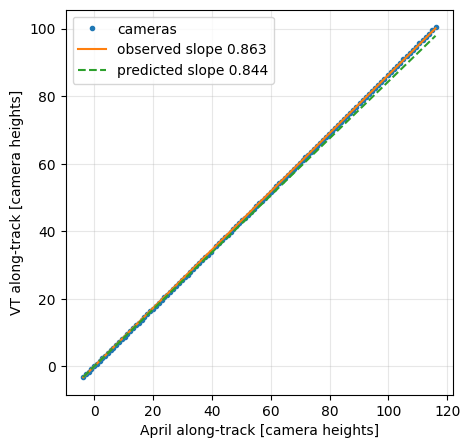

In [9]:
# Observed along-track ratio VT / April vs linear prediction
import matplotlib.pyplot as plt
from ba_obs import along_track

ref = im0['name']
sA, hA = along_track('../datasets/KBCB_colm_april', ref)
sV, hV = along_track('../datasets/KBCB_colm_vt', ref)
common = sorted(set(sA) & set(sV))
xa, xv = np.array([sA[k] for k in common]), np.array([sV[k] for k in common])

f_vt = 1614.82951   # VT fx (cameras.txt)
ratio_obs = (xa @ xv) / (xa @ xa)
ratio_pred = 1 + alpha * 100 * (f_vt - f) / f
print(f"{len(common)} common images,  camera height April {hA:.4f}, VT {hV:.4f} (COLMAP units)")
print(f"VT / April along-track:  observed {ratio_obs:.3f}   predicted {ratio_pred:.3f}")

plt.figure(figsize=(5,5))
plt.plot(xa, xv, '.', label='cameras')
plt.plot(xa, ratio_obs*xa, label=f'observed slope {ratio_obs:.3f}')
plt.plot(xa, ratio_pred*xa, '--', label=f'predicted slope {ratio_pred:.3f}')
plt.xlabel('April along-track [camera heights]')
plt.ylabel('VT along-track [camera heights]')
plt.legend()
plt.grid(alpha=0.3)
plt.show()